In [34]:
# --- CONFIGURATION ---
PROJECTION_TYPE = "linear" # Set to "pca" or "linear" to switch between result sets

# Fusion Architecture Ablation

This notebook compares different methods of fusing the Gold M signal with the Q vector.
- **Concat_M64**: Projects M to 64 dimensions and concatenates with Q.
- **Gated**: Uses M to generate a 0-1 gate to mask Q features.
- **FiLM_Scale**: Uses M directly as a scalar to scale Q features (1 + s*gamma).
- **FiLM_Full**: Uses M to both scale and shift Q features (1 + s*gamma)*Q + s*beta.

In [35]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

plt.style.use('default')
sns.set_theme(style="white", palette="muted")
plt.rcParams['figure.dpi'] = 150

def load_summary(path_str):
    path = Path(path_str)
    if path.exists():
        with open(path, 'r') as f:
            return json.load(f)
    return None

base_dir = Path(PROJECTION_TYPE)
paths = {
    'Concat (M=64)': base_dir / 'concat_m64/output/summary.json',
    'Gated': base_dir / 'gated_m64/output/summary.json',
    'FiLM (Scale)': base_dir / 'film_scale_m64/output/summary.json',
    'FiLM (Full)': base_dir / 'film_full_m64/output/summary.json'
}

data = {}
for name, path in paths.items():
    summary = load_summary(path)
    if summary:
        data[name] = summary['aggregate'][0] # Only one config per family

if data:
    print(f"Loaded {len(data)} architectures for {PROJECTION_TYPE}.")
else:
    print(f"No results found for {PROJECTION_TYPE}. Check paths.")

Loaded 4 architectures for linear.


,Fusion Architecture,Dev nDCG,Test nDCG
0,Concat (M=64),85.76,81.20
1,Gated,82.47,82.87
2,FiLM (Scale),84.53,83.12
3,FiLM (Full),87.97,83.93


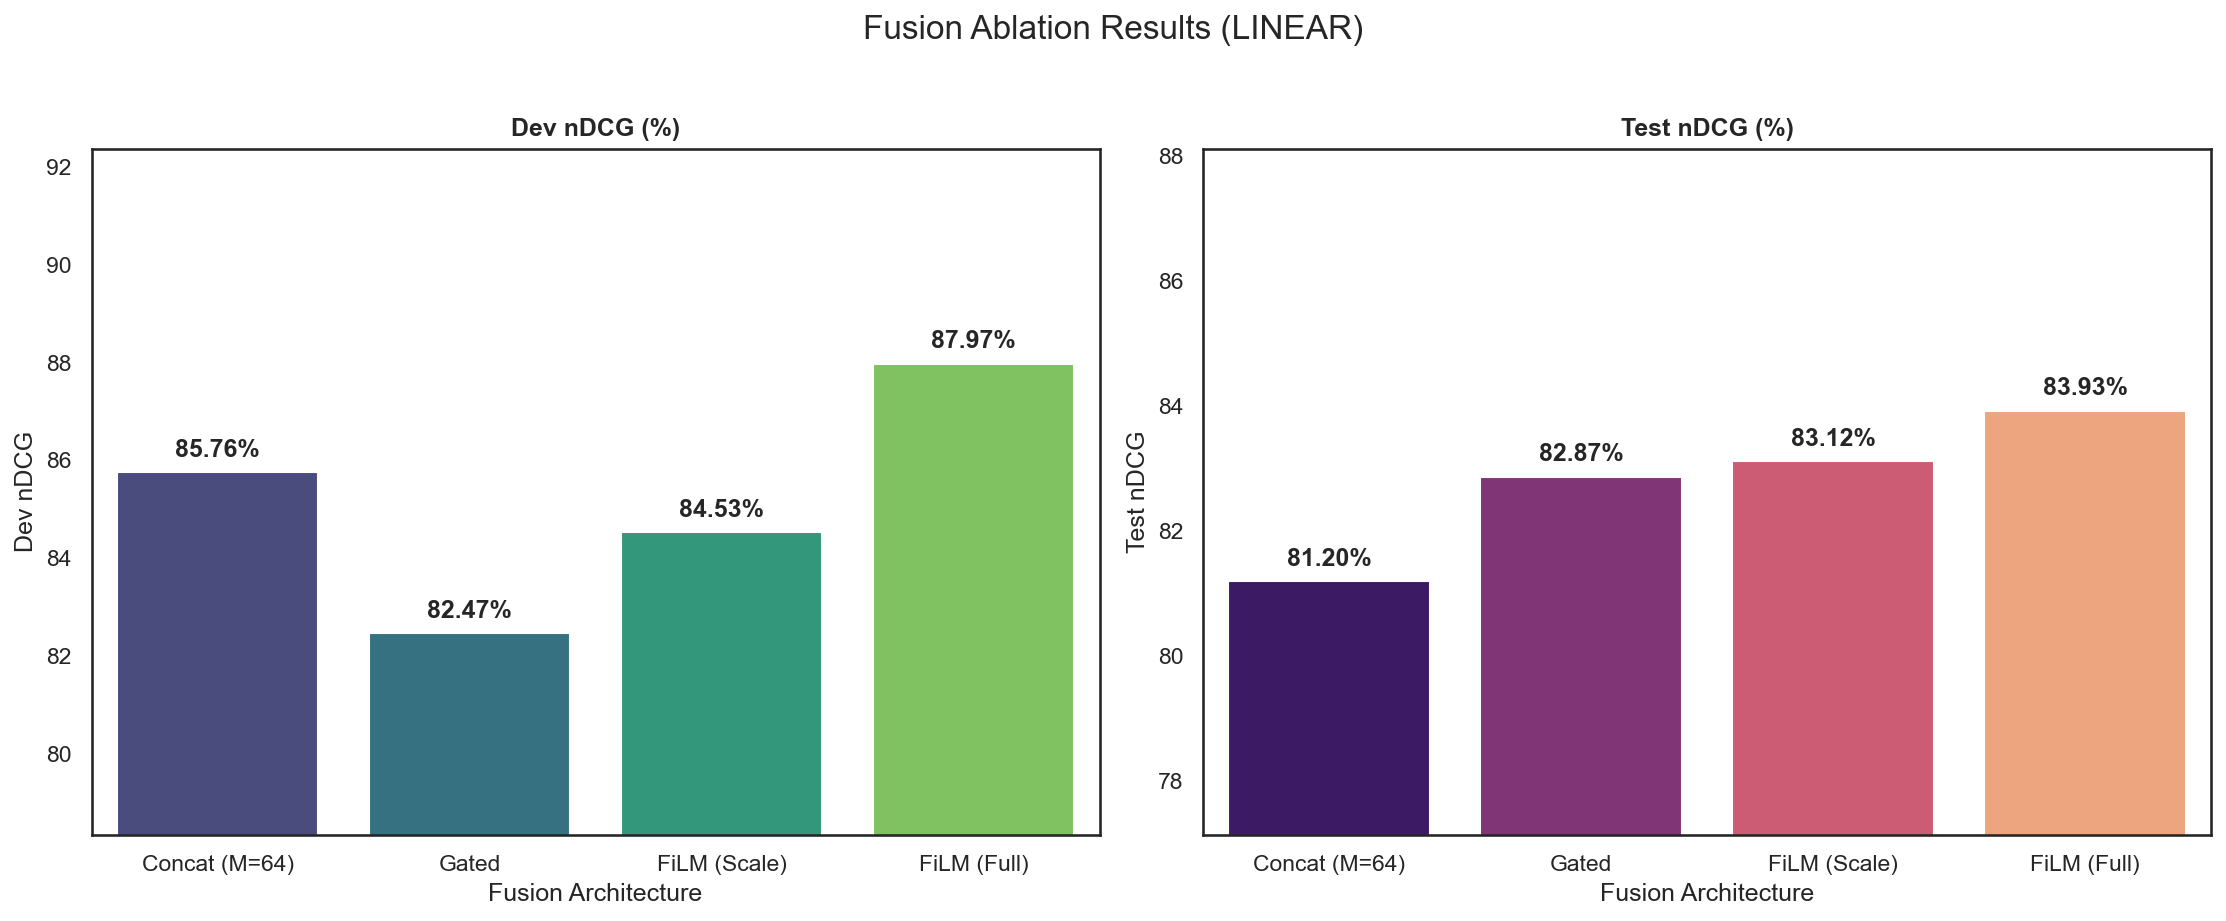

In [ ]:
if data:
    rows = []
    for name, agg in data.items():
        rows.append({
            'Fusion Architecture': name,
            'Dev nDCG': agg['best_dev']['ndcg'] * 100,
            'Test nDCG': agg['test']['ndcg'] * 100
        })
        
    df = pd.DataFrame(rows)
    display(df.round(2))
    
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    metrics = [('Dev nDCG', 'viridis', axes[0]), ('Test nDCG', 'magma', axes[1])]
    
    for metric, cmap, ax in metrics:
        sns.barplot(data=df, x='Fusion Architecture', y=metric, hue='Fusion Architecture', 
                    legend=False, palette=cmap, ax=ax)
        ax.set_title(f'{metric} (%)', fontweight='bold')
        ax.set_ylim(min(df[metric]) * 0.95, max(df[metric]) * 1.05)
        
        for p in ax.patches:
            ax.annotate(f'{p.get_height():.2f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                         ha='center', va='bottom', xytext=(0, 5), textcoords='offset points', fontweight='bold')
    
    plt.suptitle(f"Fusion Ablation Results ({PROJECTION_TYPE.upper()})", fontsize=16, y=1.02)
    plt.tight_layout()
    plt.show()